# 10. Vanilla MRAC + linear damper in Guha-Annaswamy notation

**EXPLORATORY / offline / PROXY.** Reduced taut Newton-Euler model (`QuadLoadPend`), development PC. A real (mismatched) vehicle with a payload follows a *nominal* vehicle with a nominal payload (4 kg / 2 m). The nominal vehicle is flown by the baseline PID+FF plus the linear swing damper, the slot a residual-RL policy can take later.

The law has an exact Lyapunov guarantee **on its stated model**: the linearized outer model, matched case, continuous time. The nonlinear sampled loop is validated numerically. **No stability claim is made for it.**

| Source | Where |
|---|---|
| Derivation | MQP §6.14 (`.ai/research/derivations/mrac-quadrotor-payload.md`), registry EQ-MR-22 |
| Code | `experiments/mrac/vanilla_mrac.py`; runner `mrac_lab/vanilla_runs.py` |
| Tests | `tests/mrac/test_vanilla_mrac.py`; symbolic check `check_vanilla.py` (local) |
| Architecture and v2 reconciliation | `.ai/architecture/mrac-rl-plan/17_vanilla_mrac_guha.md` |
| Paper | Guha and Annaswamy, MRAC-RL (arXiv 2011.10562), eqs. 4-6, Thm. 1-2 |

Running all cells reads saved results and evaluates closed-form quantities. It runs no episodes, tuning or training.

### Notation used across this series (added 2026-11-25)

The thesis notation (`thesis_book/residual.tex`, lines 95-292) is primary. The code and the derivation document (MQP) use their own symbols, mapped in the thesis file `.ai/research/derivations/notation-residual-tex.md`.

| This notebook / code | residual.tex | Note |
|---|---|---|
| `m_L`, `l` | $m_b$, $\ell$ | payload mass, rope length |
| `m_q`, `J`; `f`, `tau` | $m_q$, $J_q$; $f_q$, $\tau_q$ | |
| `phi` (code) | $\varphi$ | **$\varphi_{\rm tex} = -\varphi_{\rm code}$** with the cable at the vehicle CoG ($d = 0$). Odd functions of $\varphi$ flip sign; $\cos\varphi$, the tension and the tangent do not. With an offset $d\ne0$ the map is nonlinear |
| task reference `p_r(t)` | $x^d$ ("reference state" in residual.tex) | not Guha's reference model $x_r$ |

Numbers in this notebook are unchanged; only the reading of the symbols is aligned.

In [1]:
import json, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from mrac_lab import provenance

prov = provenance.setup(modules=("experiments.mrac.vanilla_mrac", "experiments.mrac.quad_load_pend"))
provenance.banner(prov, "Vanilla MRAC (EQ-MR-22)", notes=(
    "Exact result only for the continuous linear outer model with l = l_r.",
    "Inner loop, motor lag, d-coupling, ZOH, saturation and cable-length mismatch are residuals.",
))
from experiments.mrac.baselines import canonical_offline_params
from experiments.mrac.vanilla_mrac import (VanillaDesign, VanillaParams, outer_model, ideal_gains,
                                           baseline_error_gains, hover_tick_jacobian)
canon = canonical_offline_params()
RES = Path("results")
def latest(stage):
    runs = sorted(RES.glob(f"mrac_vanilla_{stage}_*"))
    return runs[-1] if runs else None

Vanilla MRAC (EQ-MR-22)
Label: EXPLORATORY / offline / PROXY (development PC, reduced taut point-load model)
Thesis checkout: C:\Users\Jcardenasbohorquez\OneDrive - Expleo France\Dokumente\Personal\thesis\gym-pymunk-quadrotor-suspended-load
Commit: 4cfea8a665fe1baa8ffdf1e53e80b5a0cee0edef (branch Claude, clean for experiments/mrac, experiments/notebook_utils/style.py, gym_pymunk_quadrotor)
Python: 3.12.3
Claim limits: No stability claim, no Pymunk-transfer claim, no hardware claim. Offline metrics are named *_off and are not the canonical c_T / c_S.
import origin: experiments.mrac.vanilla_mrac -> C:\Users\Jcardenasbohorquez\OneDrive - Expleo France\Dokumente\Personal\thesis\gym-pymunk-quadrotor-suspended-load\experiments\mrac\vanilla_mrac.py
import origin: experiments.mrac.quad_load_pend -> C:\Users\Jcardenasbohorquez\OneDrive - Expleo France\Dokumente\Personal\thesis\gym-pymunk-quadrotor-suspended-load\experiments\mrac\quad_load_pend.py
Note: Exact result only for the continuous linea

## 1. Notation (Guha ↔ this notebook ↔ code)

| Guha | Here | Meaning | Code |
|---|---|---|---|
| $x$ | $x=(y,v_y,\phi,\dot\phi,z,v_z)$ | outer state; positions relative to the task target | `outer_state` |
| $x_r$ | $x_r$ | the same coordinates of the nominal reference vehicle | |
| $A,\ \lambda B_r$ | $A,\ B=B_r\Lambda$ | plant; $\Lambda=\mathrm{diag}(\lambda_y,\lambda_z)>0$ unknown | `outer_model` |
| $A_r, B_r$ | $A_r, B_r$ | nominal pair ($m_{q,r}=9.6$, $m_{L,r}=4$, $l_r=2$) | |
| $u_r$ | $u_r$ | policy on the reference: PID+FF + softer damper | `NominalReference` |
| $(D\alpha_r)^\top e/b_r$ | $K_e^\top e$ | error feedback making $A_H$ Hurwitz | `baseline_error_gains` |
| $\xi$ | $\xi=u_r-K_e^\top e$ | | |
| $\hat K_x,\hat k_u$ | $\hat K_x\ (7\times2),\ \hat K_u\ (2\times2)$ | gains on $\bar x=(x,1)$ and on $\xi$ | |
| $\Gamma_x,\gamma_u$ | $\Gamma_x,\Gamma_u$ | elementwise positive adaptation gains | |
| $A_H, P, Q$ | $A_H=A_r-B_rK_e^\top$, $PA_H+A_H^\top P=-Q$ | Lyapunov pair | |

## 2. Outer model and matching

Assume an ideal inner attitude loop: the world force $u=(F_y,F_z)$ is realised. Drop the $d\ddot\theta$ coupling. Linearizing at taut hover ($\phi=\theta=0$, $T=m_Lg$) then gives
$$m_q\ddot y=F_y+m_Lg\phi,\qquad l\ddot\phi=-(\ddot y+g\phi),\qquad (m_q+m_L)\ddot z=F_z-(m_q+m_L)g.$$
So $\dot x=Ax+B(u-(0,Mg))$, with $A_{23}=m_Lg/m_q$, $A_{43}=-\tfrac gl(1+m_L/m_q)$, $B_{21}=1/m_q$, $B_{41}=-1/(m_ql)$ and $B_{62}=1/M$.

**Matching.**
- The cable pull $m_Lg\phi$ enters the $v_y$ and $\dot\phi$ rows in the ratio $1:-1/l$. That is exactly the $F_y$ column of $B$.
- So, for $l=l_r$: $B=B_r\Lambda$ with $\Lambda=\mathrm{diag}(m_{q,r}/m_q,\ M_r/M)$.
- $A_r-A=B_r\Lambda K_x^{*\top}$ has the exact solution $K_x^*[\phi,F_y]=g(m_qm_{L,r}/m_{q,r}-m_L)$.
- Gravity is matched by the constant entry, $K_x^*[1,F_z]=Mg$; $K_u^*=\Lambda^{-1}$.
- **Payload and vehicle mass mismatch are matched. Cable length is not:** for $l\ne l_r$ no ideal exists.

In [2]:
for label, (mq, mL, l) in {"payload 6 kg": (9.6, 6.0, 2.0), "payload 2 kg": (9.6, 2.0, 2.0),
                           "vehicle x1.2": (11.52, 4.0, 2.0), "length 2.5 m (unmatched)": (9.6, 4.0, 2.5)}.items():
    lam, kx, ku, res = ideal_gains(mq, mL, l, m_qr=9.6, m_Lr=4.0, l_r=2.0, g=9.81)
    print(f"{label:26s} Lambda={np.round(lam,4)}  Kx*[phi,Fy]={kx[2,0]:+8.3f}  Kx*[1,Fz]={kx[6,1]:8.3f}  matching residual={res:.2e}")

payload 6 kg               Lambda=[1.     0.8718]  Kx*[phi,Fy]= -19.620  Kx*[1,Fz]= 153.036  matching residual=4.44e-16
payload 2 kg               Lambda=[1.     1.1724]  Kx*[phi,Fy]= +19.620  Kx*[1,Fz]= 113.796  matching residual=4.58e-16
vehicle x1.2               Lambda=[0.8333 0.8763]  Kx*[phi,Fy]=  +7.848  Kx*[1,Fz]= 152.251  matching residual=3.14e-16
length 2.5 m (unmatched)   Lambda=[1. 1.]  Kx*[phi,Fy]=  +5.337  Kx*[1,Fz]= 133.416  matching residual=1.25e+00


## 3. Reference model, swing error and the error feedback

The reference is the nominal plant flown by the baseline: PID+FF (mass-blind, $\hat m=4$) plus the softer damper $G(-1,-0.5)$ in fixed form. The error $e=x-x_r$ **contains the swing error** $\phi-\phi_r$ and its rate.

$K_e$ holds the baseline's own outer gains:
- **PID part:** PD per axis with the PID mass.
- **Damper part:** the softer damper's torque, mapped through the attitude PD at quasi-steady state. This gives the lateral force $-c(k_{p,s}e_\phi+k_{d,s}e_{\dot\phi}/\omega_0)$, with $c=f_r\beta_\tau\tau_{max}/(Jk_{p,\theta})$.

The linear damper therefore acts on the swing *error* inside the error dynamics $A_H$.

In [3]:
for damper in (True, False):
    d = VanillaDesign.build(canon, VanillaParams(swing_damper=damper))
    ev = np.linalg.eigvals(d.A_H)
    print("K_e with damper" if damper else "K_e PID only   ", np.round(sorted(ev, key=lambda c: (c.real, c.imag)), 3))
d = VanillaDesign.build(canon, VanillaParams())
print("lambda_min(P) =", np.linalg.eigvalsh(d.P).min().round(4), "  K_e^T =\n", d.K_e.T.round(2))

K_e with damper [-1.059-1.619j -1.059+1.619j -0.955-2.953j -0.955+2.953j -0.398-0.981j
 -0.398+0.981j]
K_e PID only    [-1.059-1.619j -1.059+1.619j -0.657-1.095j -0.657+1.095j -0.343-2.549j
 -0.343+2.549j]
lambda_min(P) = 0.2416   K_e^T =
 [[ 21.12  19.2  -60.02 -13.55   0.     0.  ]
 [  0.     0.     0.     0.    50.88  28.8 ]]


## 4. Law, Lyapunov function and what it proves

$$u=\hat K_x^\top\bar x+\hat K_u^\top\xi,\qquad \dot{\hat K}_x=-\Gamma_x\odot(\bar x\,e^\top PB_r),\qquad \dot{\hat K}_u=-\Gamma_u\odot(\xi\,e^\top PB_r).$$

**Error equation.** With $\tilde K=\hat K-K^*$: $\dot e=A_He+B_r\Lambda(\tilde K_x^\top\bar x+\tilde K_u^\top\xi)$.

**Storage.** $V=e^\top Pe+\sum_{ij}\Lambda_j(\tilde K_x)_{ij}^2/(\Gamma_x)_{ij}+\sum_{ij}\Lambda_j(\tilde K_u)_{ij}^2/(\Gamma_u)_{ij}$.

**Derivative.** The cross term $2e^\top PB_r\Lambda\tilde K_x^\top\bar x=2\sum_{ij}\Lambda_j(\tilde K_x)_{ij}\bar x_i(e^\top PB_r)_j$ cancels the gain term exactly, because $\Lambda$ is diagonal. Hence
$$\dot V=-e^\top Qe\le 0.$$

**Consequences.**
- $e$ and $\tilde K$ are bounded; $e\in L_2$; $\dot e$ is bounded.
- **Barbalat gives $e\to0$** (Guha Thm. 2: bounded reference, matched case, continuous time).
- **Parameter convergence is not implied.** It needs persistent excitation of $(\bar x,\xi)$.
- At hover only the constant entry is excited.

**Robust modifications.**
- *Projection* on boxes containing the family ideals keeps $\dot V\le0$.
- *σ-modification* toward the nominal gives $\dot V\le-cV+\tfrac\sigma2\|K^*-K_0\|^2$, so UUB with a nonzero steady error. This is the offset seen in the A0 runs.

**Known RBF disturbance weights** $\hat W^\top\Phi_d(v)$ use the same cancellation:
- exact representation: $e\to0$;
- representation error $\le\bar\epsilon$: $\|e\|$ ultimately $\le 2\|PB_r\Lambda\|\bar\epsilon/\lambda_{\min}(Q)$;
- time-varying wind is not a state function, so it is UUB only.

## 5. Before tuning: the sampled implementation is checked locally

The proof is continuous-time and assumes an ideal inner loop. The real tick has ZOH at 50 Hz, motor lag, the attitude PD and Euler updates. Before any tuning we therefore take a central finite-difference Jacobian of **one real tick** at taut hover, with the plant's ideal gains (an exact equilibrium).

- The 16 gain entries that multiply signals vanishing at hover are exactly neutral (eigenvalue 1, no excitation). They are excluded.
- On the other modes, a negative growth rate means local exponential stability at that plant.

At high gain on the constant entry the **lateral** bias column couples with the swing and grows. That is why the lateral column multiplier $c_y$ exists. The tuning grid is run only on designs that pass this check (the runner's preflight gate).

In [4]:
rows = []
for mL in (2.0, 4.0, 6.0):
    c = canon.with_condition(m_L=mL, cable_length=2.0)
    for gc in (20.0, 500.0, 1000.0, 2000.0):
        for cy in (1.0, 0.25):
            r = hover_tick_jacobian(c, VanillaDesign.build(c, VanillaParams(gamma_x=(20.0,)*6 + (gc,), gamma_cols=(cy, 1.0))))
            rows.append(dict(m_L=mL, gamma_const=gc, c_y=cy, n_neutral=r["n_neutral"], growth_rate_per_s=round(r["growth_rate_per_s"], 4)))
tab = pd.DataFrame(rows).pivot_table(index=["gamma_const", "c_y"], columns="m_L", values="growth_rate_per_s")
display(tab)

m_L                  2.0     4.0     6.0
gamma_const c_y                         
20.0        0.25 -0.0045 -0.0038 -0.0033
            1.00 -0.0045 -0.0038 -0.0033
500.0       0.25 -0.0942 -0.0825 -0.0734
            1.00 -0.0942 -0.0825 -0.0734
1000.0      0.25 -0.1592 -0.1425 -0.1288
            1.00 -0.0831 -0.0483 -0.0106
2000.0      0.25 -0.1565 -0.1335 -0.1055
            1.00 -0.0711 -0.0303  0.0122

## 6. Why the A0 law (NB07, NB09) did not converge

From the saved A0 CSVs (`02_convergence_analysis.md`; no new episodes):
- During the 4 s transfer the regressor has rank 3, and the means of $\hat m_q$ and $\hat m_L$ land near the truth.
- After it, the Gramian has **rank 1**: the $m_q$ and $m_L$ columns are identical at hover (correlation 1.000; condition number above $10^9$ after 10 s).
- Only the lumped $\hat M$ is informed, and it oscillates with growing amplitude: std 1.40, then 1.62, then 2.61 kg. That is the C3 mode, with $\Gamma_{mL}=3$ dominating.
- σ freezes $\hat M$ at a biased value (15.53 against 15.6), which gives the offset.
- So "not converging" is structural non-identifiability plus a sampled-data adaptive mode, not a mis-set gain.

The vanilla law keeps the swing error inside $e$, has no tilt filter (C1 removed), and does not cancel the measured swing (C2 removed). C3 has a vanilla analogue, the constant-entry gains (§5). It is handled by restricting the gains to the certified region.

## 7. Validation (approved under D1, 2026-11-25)

### 7.1 Linear outer plant: the theorem's own setting

In [5]:
VAL = latest("validation")
print("validation run:", VAL)
rec = json.loads((VAL / "receipt.json").read_text())
print("status", rec["status"], " wall", round(rec["wall_s"]), "s  commit", rec["thesis_commit"][:7], " dirty paths:", rec["dirty_paths"])
summ = pd.DataFrame(json.loads((VAL / "summary.json").read_text()))
lin = summ[summ.kind == "linear"][["id", "m_L", "scenario", "sampled", "V0", "V_end", "V_max_increase", "norm_e_max", "norm_e_end", "Kx_tilde_0", "Kx_tilde_end", "matching_residual"]]
display(lin.sort_values("id").round(6))

validation run: results\mrac_vanilla_validation_20261125T020307
status completed  wall 1410 s  commit 2a329ad  dirty paths: ['xperiments/mrac/payload_law.py', 'experiments/mrac/payload_reference.py', 'experiments/mrac/quad_load_pend.py', 'experiments/mrac/diagnostics.py', 'experiments/mrac/vanilla_mrac.py', 'experiments/mrac/wind.py']


,id,m_L,scenario,sampled,V0,V_end,V_max_increase,norm_e_max,norm_e_end,Kx_tilde_0,Kx_tilde_end,matching_residual
4,lin_m2_pe_cont,2.0,pe,NaN,20.175203,18.944930,-0.000000,0.468002,0.005756,27.74687,19.413775,0.0
2,lin_m2_pe_zoh,2.0,pe,0.02,20.175203,18.928850,0.000314,0.477005,0.018539,27.74687,19.405253,0.0
3,lin_m2_step_cont,2.0,step,NaN,20.175203,19.509762,0.000000,0.404437,0.000000,27.74687,20.422932,0.0
0,lin_m2_step_zoh,2.0,step,0.02,20.175203,19.475847,0.009498,0.412460,0.000000,27.74687,20.404673,0.0
10,lin_m4_pe_cont,4.0,pe,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.0
6,lin_m4_pe_zoh,4.0,pe,0.02,0.000000,0.018023,0.000010,0.032559,0.020882,0.00000,0.592618,0.0
5,lin_m4_step_cont,4.0,step,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.0
1,lin_m4_step_zoh,4.0,step,0.02,0.000000,0.000140,0.011849,0.189897,0.000000,0.00000,0.073490,0.0
11,lin_m6_pe_cont,6.0,pe,NaN,19.937259,19.128400,-0.000000,0.393673,0.002149,27.74687,19.506217,0.0
9,lin_m6_pe_zoh,6.0,pe,0.02,19.937259,19.138034,0.000226,0.404585,0.021564,27.74687,19.501139,0.0


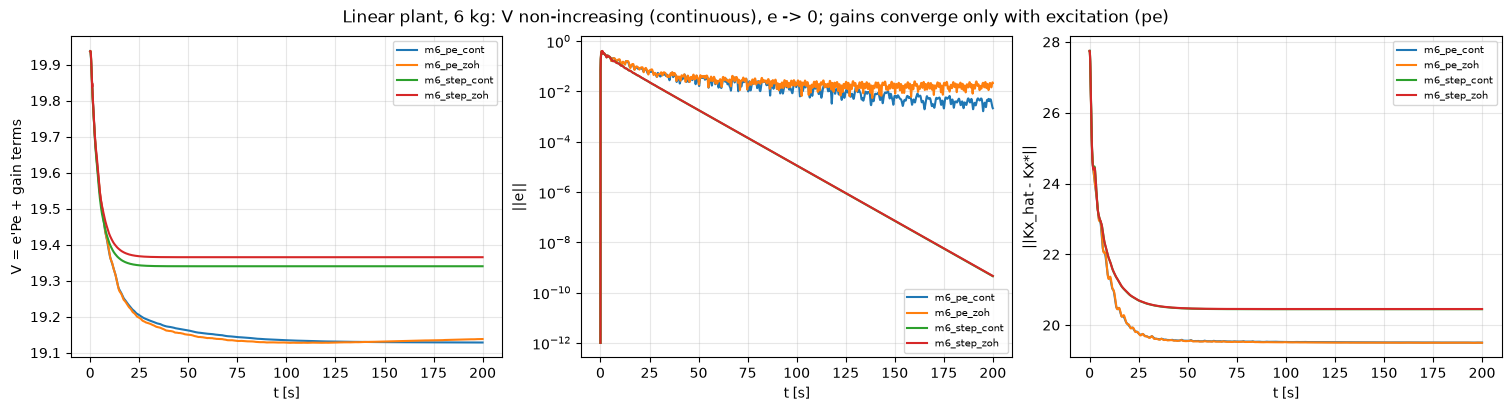

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for f in sorted(VAL.glob("lin_lin_m6_*.npz")):
    z = np.load(f); lab = f.stem.replace("lin_lin_", "")
    ax[0].plot(z["t"], z["V"], label=lab); ax[1].semilogy(z["t"], z["norm_e"] + 1e-12, label=lab)
    ax[2].plot(z["t"], np.linalg.norm(z["Kx"] - z["ideal_Kx"], axis=(1, 2)), label=lab)
ax[0].set_ylabel("V = e'Pe + gain terms"); ax[1].set_ylabel("||e||"); ax[2].set_ylabel("||Kx_hat - Kx*||")
for a in ax: a.set_xlabel("t [s]"); a.grid(alpha=.3); a.legend(fontsize=7)
fig.suptitle("Linear plant, 6 kg: V non-increasing (continuous), e -> 0; gains converge only with excitation (pe)");

### 7.2 Reduced nonlinear plant: ONLINE vs FROZEN vs direct softer baseline (120 s)

In [7]:
nl = summ[(summ.kind == "nonlinear") & summ.id.str.startswith("nl_")].copy()
nl["cell"] = nl.apply(lambda r: f"m{r.m_L:g}_L{r.L:g}_{r.scenario}", axis=1)
cols = ["task_rms_last30", "ref_err_rms_last30", "swing_rms_10_30", "swing_rms_last30", "mean_z_last30", "sat_frac", "status"]
display(nl.pivot_table(index="cell", columns="arm", values=["task_rms_last30", "swing_rms_10_30"], aggfunc="first").round(4))
display(nl[["id", "status", "stop", "t_end"]].query("status != 'completed'"))

swing_rms_10_30                 task_rms_last30          \
arm                       frozen  online  softer          frozen  online   
cell                                                                       
m2_L1.5_hover             0.0267  0.0071  0.0011          0.2431  0.0004   
m2_L1.5_transfer          0.0267  0.0243  0.0027          0.2431  0.0004   
m2_L2_hover               0.0002  0.0031  0.0017          0.3856  0.0004   
m2_L2_transfer            0.0018  0.0088  0.0040          0.3856  0.0004   
m4_L1.5_hover             0.0044  0.0035  0.0000          0.0190  0.0000   
m4_L1.5_transfer          0.0032  0.0069  0.0004          0.0187  0.0000   
m4_L2.5_hover             0.0003  0.0054  0.0003          0.0000  0.0000   
m4_L2.5_transfer          0.0010  0.0088  0.0018          0.0000  0.0000   
m4_L2_hover               0.0002  0.0002  0.0002          0.0000  0.0000   
m4_L2_transfer            0.0011  0.0011  0.0010          0.0000  0.0000   
m6_L2.5_hover             0.0003  0.0085  0.0001          0.3856  0.0004   
m6_L2.5_transfer          0.0008  0.0140  0.0007          0.3856  0.0004   
m6_L2_hover               0.0002  0.0022  0.0001          0.3856  0.0004   
m6_L2_transfer            0.0008  0.0049  0.0003          0.3856  0.0004   

                         
arm              softer  
cell                     
m2_L1.5_hover       0.0  
m2_L1.5_transfer    0.0  
m2_L2_hover         0.0  
m2_L2_transfer      0.0  
m4_L1.5_hover       0.0  
m4_L1.5_transfer    0.0  
m4_L2.5_hover       0.0  
m4_L2.5_transfer    0.0  
m4_L2_hover         0.0  
m4_L2_transfer      0.0  
m6_L2.5_hover       0.0  
m6_L2.5_transfer    0.0  
m6_L2_hover         0.0  
m6_L2_transfer      0.0

,id,status,stop,t_end


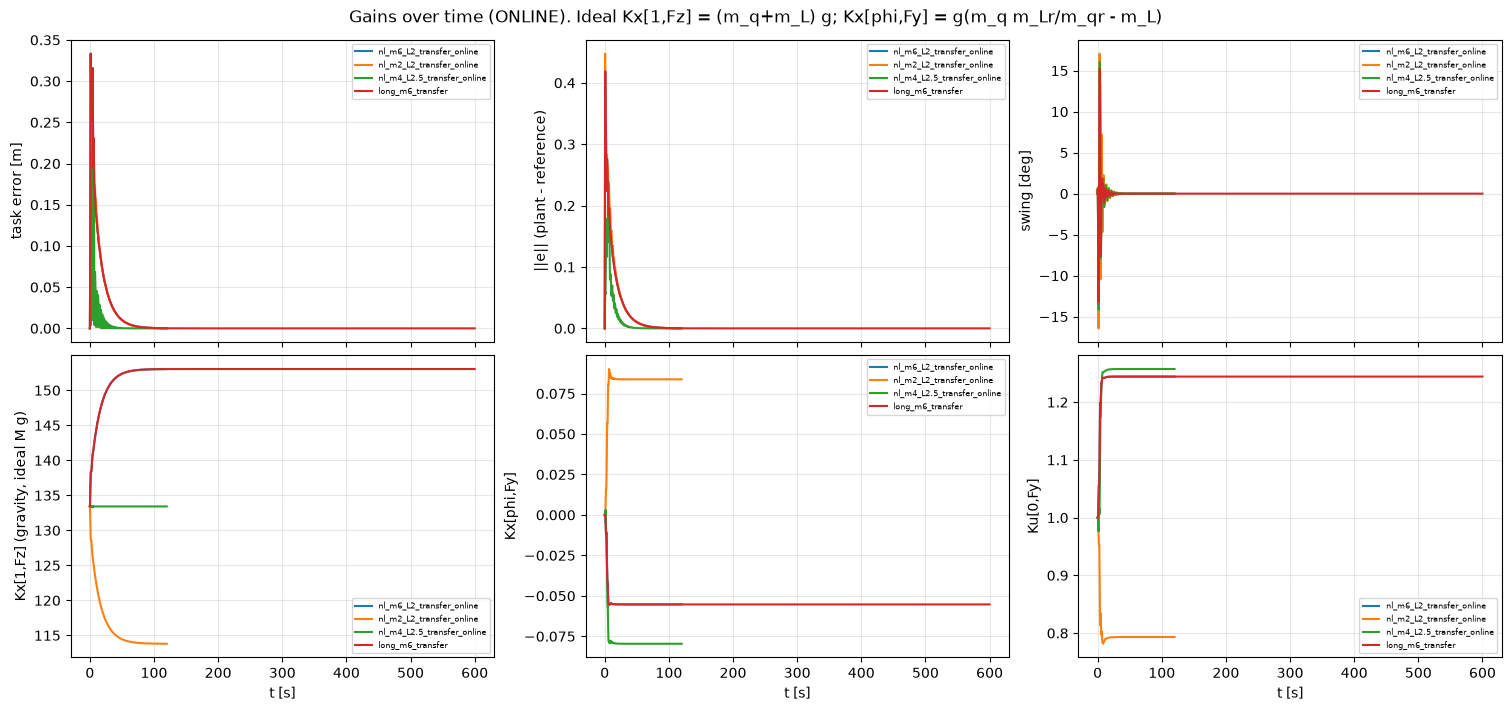

In [8]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7), sharex=True, constrained_layout=True)
for name in ("nl_m6_L2_transfer_online", "nl_m2_L2_transfer_online", "nl_m4_L2.5_transfer_online", "long_m6_transfer"):
    f = VAL / f"{name}.csv"
    if not f.exists():
        continue
    df = pd.read_csv(f)
    ax[0, 0].plot(df.t, np.hypot(df.y, df.z), label=name); ax[0, 1].plot(df.t, df.norm_e, label=name)
    ax[0, 2].plot(df.t, np.degrees(df.phi), label=name)
    ax[1, 0].plot(df.t, df.Kx_one_Fz, label=name); ax[1, 1].plot(df.t, df.Kx_phi_Fy, label=name)
    ax[1, 2].plot(df.t, df.Ku_0_Fy, label=name)
for a, l in zip(ax.flat, ["task error [m]", "||e|| (plant - reference)", "swing [deg]", "Kx[1,Fz] (gravity, ideal M g)", "Kx[phi,Fy]", "Ku[0,Fy]"]):
    a.set_ylabel(l); a.grid(alpha=.3); a.legend(fontsize=6)
for a in ax[1]: a.set_xlabel("t [s]")
fig.suptitle("Gains over time (ONLINE). Ideal Kx[1,Fz] = (m_q+m_L) g; Kx[phi,Fy] = g(m_q m_Lr/m_qr - m_L)");

### 7.3 σ-modification and long horizon

In [9]:
sig = summ[summ.id.str.startswith("sig_") | summ.id.str.startswith("long_")]
display(sig[["id", "status", "t_end", "task_rms_last30", "ref_err_rms_last30", "mean_z_last30", "Kx_one_Fz_last", "ideal_Kx_one_Fz", "Kx_one_Fz_std_last30"]].round(4))

,id,status,t_end,task_rms_last30,ref_err_rms_last30,mean_z_last30,Kx_one_Fz_last,ideal_Kx_one_Fz,Kx_one_Fz_std_last30
15,sig_m2_L2_hover,completed,119.9,0.1810,0.1810,0.1810,124.5237,113.796,0.0001
20,sig_m2_L2_transfer,completed,119.9,0.1810,0.1810,0.1810,124.5237,113.796,0.0001
23,sig_m4_L2_hover,completed,119.9,0.0000,0.0000,0.0000,133.4160,133.416,0.0000
28,sig_m4_L2_transfer,completed,119.9,0.0000,0.0000,-0.0000,133.4160,133.416,0.0000
31,sig_m6_L2_hover,completed,119.9,0.1810,0.1810,-0.1810,142.3083,153.036,0.0001
36,sig_m6_L2_transfer,completed,119.9,0.1810,0.1810,-0.1810,142.3083,153.036,0.0001
40,sig_m4_L1.5_hover,completed,119.9,0.0000,0.0000,-0.0000,133.4160,133.416,0.0000
43,sig_m4_L1.5_transfer,completed,119.9,0.0000,0.0000,0.0000,133.4160,133.416,0.0000
48,sig_m4_L2.5_hover,completed,119.9,0.0000,0.0000,0.0000,133.4160,133.416,0.0000
52,sig_m4_L2.5_transfer,completed,119.9,0.0000,0.0000,0.0000,133.4160,133.416,0.0000


### 7.4 Disturbances: none / constant / OU / periodic gust / drag in a steady wind, with and without RBF weights (6 kg / 2 m transfer)

Each disturbance is run independently, with the no-disturbance case as control. `rbf` uses 15 Gaussian RBFs on vehicle velocity with $\sigma_W=0$; `rbfs` uses $\sigma_W=0.1$. The constant regressor entry already estimates constant forces.

In [10]:
dist = summ[summ.id.str.startswith("dist_")].copy()
dist["wind"] = dist.id.str.extract(r"dist_([a-z]+)\d")
dist["arm2"] = dist.id.str.split("_").str[-1]
display(dist.pivot_table(index=["wind", "seed"], columns="arm2", values="task_rms_last30").round(4))
display(dist.pivot_table(index=["wind", "seed"], columns="arm2", values="mean_y_last30").round(4))

arm2            V0  frozen     rbf    rbfs
wind  seed                                
const 0.0   0.0006  0.5238  0.0001  0.0015
drag  0.0   0.0004  0.5250  0.0001  0.0011
gust  0.0   0.1008  0.5251  0.0874  0.0859
none  0.0   0.0004  0.3856  0.0001  0.0012
ou    1.0   0.0464  0.5359  0.0414  0.0417
      2.0   0.0481  0.4892  0.0394  0.0399
      3.0   0.0436  0.4881  0.0374  0.0368

arm2            V0  frozen     rbf    rbfs
wind  seed                                
const 0.0   0.0000  0.2779  0.0000  0.0001
drag  0.0   0.0000  0.3586  0.0000  0.0001
gust  0.0   0.0009  0.2353 -0.0029 -0.0026
none  0.0  -0.0000 -0.0000 -0.0000 -0.0000
ou    1.0   0.0034  0.2610  0.0032  0.0031
      2.0  -0.0106  0.2193 -0.0090 -0.0095
      3.0  -0.0053  0.1767 -0.0042 -0.0050

## 8. Tuning (protocols 03 and 06)

**T1 / T2 (protocol 03).** The swing gate G3 (half the softer law's benefit) was about 0.02 deg at 6 kg. It rejected every fast adapter, so the slowest design was selected. On T2 that design was **not good enough**, and V0 beat it in 17 of 21 cells.

**T1' / T2' (protocol 06, chosen by Javier).**
- G3' = `max(B_S, 0.005 rad)`. The floor was set after T1 was seen, so T1' is a re-analysis of the same deterministic episodes.
- T2' is a fresh held-out test with 4 never-seen conditions. It ran as two parts (wall cap), combined per AM7.
- **Result:** TUNED' tracks at about 1e-5 m and beats V0 in 30 cells. All 12 never-seen cells pass G1 and G2.
- **Strict "good enough": NO.** Three cells fail it: two light-load fast transfers that leave the taut-cable domain for every controller, and the 2 kg / 1.5 m short-rope case (saturation and swing).
- Javier decides whether these are domain limits (report `07_t1prime_t2prime_report.md`, thesis `.ai/work`, local).

In [11]:
T1 = RES / "mrac_vanilla_tune_20261125T024907"
for name in ("analysis", "analysis_t1prime"):
    an = json.loads((T1 / f"{name}.json").read_text())
    print(f"{name}: floor {an.get('g3_floor_rad', 0.0)} | pass {an['n_pass']}/{an['n_designs']} | gate failures {an['fail_counts']} | selected {an['selected']['tag']} ({an['selected']['mean_task_rms_last30']:.2e} m)")
an = json.loads((T1 / "analysis_t1prime.json").read_text())
display(pd.DataFrame([dict(tag=d["tag"], passes=d["pass"], mean_task_rms_last30=d["mean_task_rms_last30"],
                           G3_failed_cells=", ".join(d["G3_cells_failed"])) for d in an["all_designs"]]).head(15))

analysis: floor 0.0 | pass 6/54 | gate failures {'G1': 0, 'G2': 0, 'G3': 48} | selected gs5_gc200_cy0.25_gu0.3_s0 (2.19e-02 m)
analysis_t1prime: floor 0.005 | pass 42/54 | gate failures {'G1': 0, 'G2': 0, 'G3': 12} | selected gs5_gc1000_cy0.25_gu0.3_s0 (1.87e-05 m)


,tag,passes,mean_task_rms_last30,G3_failed_cells
0,gs5_gc1000_cy0.25_gu0.3_s0,True,0.000019,
1,gs20_gc1000_cy0.25_gu0.3_s0,True,0.000019,
2,gs80_gc1000_cy0.25_gu0.3_s0,True,0.000019,
3,gs5_gc1000_cy0.25_gu1_s0,True,0.000035,
4,gs20_gc1000_cy0.25_gu1_s0,True,0.000035,
5,gs80_gc1000_cy0.25_gu1_s0,True,0.000036,
6,gs5_gc1000_cy0.25_gu3_s0,True,0.000108,
7,gs20_gc1000_cy0.25_gu3_s0,True,0.000108,
8,gs80_gc1000_cy0.25_gu3_s0,True,0.000108,
9,gs80_gc1000_cy1_gu3_s0,False,0.000363,"m2_L2_q1_hover, m2_L2_q1_transfer, m6_L2_q1_ho..."


In [12]:
for label, folder, name in (("T2 (protocol 03)", "mrac_vanilla_heldout_20261125T034506", "analysis"),
                            ("T2' (protocol 06, composite)", "mrac_vanilla_heldout_composite_20261125T111150", "analysis_t2prime")):
    ah = json.loads((RES / folder / f"{name}.json").read_text())
    print(f"== {label}: good_enough={ah['good_enough']} | crit2 {ah['criterion2_adaptation_benefit']} | crit3 {ah['criterion3_swing']} | regressions vs V0 {ah['regressions_vs_v0']} | V0 beats tuned in {len(ah['v0_beats_tuned'])} cells")
ah = json.loads((RES / "mrac_vanilla_heldout_composite_20261125T111150" / "analysis_t2prime.json").read_text())
cells = pd.DataFrame(ah["cells"])
cells["unseen"] = cells.cell.str.startswith(("m3_L2_", "m5_L2_", "m4_L1.75_", "m4_L2_q0.85"))
display(cells[["cell", "unseen", "matched", "G1", "G2", "G3", "tuned_online_task", "tuned_frozen_task", "v0_online_task",
               "tuned_swing_10_30", "B_S", "tuned_status"]].round(5))

== T2 (protocol 03): good_enough=False | crit2 8/8 matched cells with both arms completed (9 matched cells in total) | crit3 16/19 evaluable (2 not evaluable: a baseline failed, AM5) | regressions vs V0 ['m2.5_L2_q1_transfer_fast'] | V0 beats tuned in 17 cells
== T2' (protocol 06, composite): good_enough=False | crit2 17/17 matched cells with both arms completed (18 matched cells in total) | crit3 27/30 evaluable (3 not evaluable: a baseline failed, AM5) | regressions vs V0 ['m2.5_L2_q1_transfer_fast'] | V0 beats tuned in 1 cells


,cell,unseen,matched,G1,G2,G3,tuned_online_task,tuned_frozen_task,v0_online_task,tuned_swing_10_30,B_S,tuned_status
0,m2.5_L2_q1_hover,False,True,True,True,True,0.00000,0.28921,0.00018,0.00041,0.00500,completed
1,m2.5_L2_q1_transfer,False,True,True,True,True,0.00000,0.28921,0.00018,0.00261,0.01170,completed
2,m2.5_L2_q1_transfer_fast,False,True,False,False,None,NaN,NaN,0.00013,NaN,NaN,failed
3,m2_L1.5_q1_hover,False,False,False,True,False,0.00003,0.24305,0.00040,0.02048,0.00500,completed
4,m2_L1.5_q1_transfer,False,False,True,True,False,0.00002,0.24305,0.00040,0.01702,0.00606,completed
5,m2_L1.5_q1_transfer_fast,False,False,False,False,None,NaN,NaN,NaN,NaN,NaN,failed
6,m3_L2_q1_hover,True,True,True,True,True,0.00000,0.19281,0.00007,0.00027,0.00500,completed
7,m3_L2_q1_transfer,True,True,True,True,True,0.00000,0.19281,0.00007,0.00197,0.00902,completed
8,m3_L2_q1_transfer_fast,True,True,True,True,None,0.00000,0.19281,0.00006,0.00221,NaN,completed
9,m4_L1.5_q1_hover,False,False,True,True,True,0.00001,0.01895,0.00000,0.00118,0.00500,completed


## 9. Claim limits and next step

- **Proved:** for the continuous, linearized, matched outer model, $\dot V=-e^\top Qe$ and $e\to0$ (Barbalat). Projection keeps this; σ gives UUB.
- **Not proved:** anything for the nonlinear sampled loop with its inner attitude loop, motor lag, saturation or length mismatch. The episodes are local, finite-horizon, single-machine evidence (PROXY).
- **Not claimed:** parameter convergence without PE; real-swing damping beyond the regulated swing error.
- **Next:** with Javier's approval, replace the damper inside $u_r$ by the frozen residual policy (Guha Fig. 1b). The proof structure is unchanged if the reference stays bounded. Pymunk transfer stays blocked until the offline model is accepted.